In [1]:

import pandas as pd
import numpy as np

data = {
    "order_id": list(range(1, 21)),
    "customer_name": [
        "Amit", "Riya", "Neha", "Raj", "Priya",
        "Aman", "Karan", "Mira", "Jay", "Tina",
        "Dev", "Sara", "Om", "Diya", "Arjun",
        "Nisha", "Yash", "Isha", "Manav", "Kavya"
    ],
    "restaurant_name": [
        "Spice Hub", "Pizza Point", "Green Bowl", "Burger House",
        "Spice Hub", "Cafe Bean", "Pizza Point", "Green Bowl",
        "Burger House", "Cafe Bean", "Spice Hub", "Pizza Point",
        "Green Bowl", "Burger House", "Cafe Bean", "Spice Hub",
        "Pizza Point", "Green Bowl", "Burger House", "Cafe Bean"
    ],
    "category": [
        "Indian", "Italian", "Healthy", "Fast Food", "Indian",
        "Cafe", "Italian", "Healthy", "Fast Food", "Cafe",
        "Indian", "Italian", "Healthy", "Fast Food", "Cafe",
        "Indian", "Italian", "Healthy", "Fast Food", "Cafe"
    ],
    "delivery_time_mins": [
        25, 30, np.nan, 40, 28, 20, 35, 32, 45, 22,
        27, 31, 29, np.nan, 24, 26, 38, 33, 42, 23
    ],
    "order_value": [
        250, 400, 300, 500, np.nan, 200, 450, 350, 600, 180,
        280, 420, 320, 550, 220, 270, 10000, 340, 580, np.nan
    ],
    "rating": [
        4.5, 4.0, 4.2, np.nan, 4.6, 3.9, 4.1, 4.3, 3.8, 4.4,
        4.7, 4.0, 4.2, 3.7, 4.5, 4.6, np.nan, 4.1, 3.9, 4.3
    ]
}

# Create DataFrame
df = pd.DataFrame(data)

# Introduce one missing categorical value
df.loc[2, "category"] = np.nan

# Add three duplicate rows
df = pd.concat(
    [df, df.iloc[[0, 1, 2]]],
    ignore_index=True
)

# Display the dataset
print(df)

# Check dataset information
print("\nDataset information:")
df.info()

# Count missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check dataset shape
print("\nDataset shape:", df.shape)


    order_id customer_name restaurant_name   category  delivery_time_mins  \
0          1          Amit       Spice Hub     Indian                25.0   
1          2          Riya     Pizza Point    Italian                30.0   
2          3          Neha      Green Bowl        NaN                 NaN   
3          4           Raj    Burger House  Fast Food                40.0   
4          5         Priya       Spice Hub     Indian                28.0   
5          6          Aman       Cafe Bean       Cafe                20.0   
6          7         Karan     Pizza Point    Italian                35.0   
7          8          Mira      Green Bowl    Healthy                32.0   
8          9           Jay    Burger House  Fast Food                45.0   
9         10          Tina       Cafe Bean       Cafe                22.0   
10        11           Dev       Spice Hub     Indian                27.0   
11        12          Sara     Pizza Point    Italian                31.0   

In [2]:

# Check missing values before filling
print("Null values before filling:")
print(df.isnull().sum())

# Fill numeric columns with median
df['delivery_time_mins'] = df['delivery_time_mins'].fillna(
    df['delivery_time_mins'].median()
)

df['order_value'] = df['order_value'].fillna(
    df['order_value'].median()
)

# Fill rating with mean rounded to 1 decimal
df['rating'] = df['rating'].fillna(
    round(df['rating'].mean(), 1)
)

# Fill category with mode
df['category'] = df['category'].fillna(
    df['category'].mode()[0]
)

# Check missing values after filling
print("\nNull values after filling:")
print(df.isnull().sum())


Null values before filling:
order_id              0
customer_name         0
restaurant_name       0
category              2
delivery_time_mins    3
order_value           2
rating                2
dtype: int64

Null values after filling:
order_id              0
customer_name         0
restaurant_name       0
category              0
delivery_time_mins    0
order_value           0
rating                0
dtype: int64


In [3]:

print("Shape before removing duplicates:", df.shape)

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape before removing duplicates: (23, 7)
Shape after removing duplicates: (20, 7)


In [4]:

# Calculate Q1, Q3 and IQR
Q1 = df['order_value'].quantile(0.25)
Q3 = df['order_value'].quantile(0.75)

IQR = Q3 - Q1

# Calculate lower and upper fences
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)

# Display outlier rows
outliers = df[
    (df['order_value'] < lower_fence) |
    (df['order_value'] > upper_fence)
]

print("\nOutlier rows:")
print(outliers)

# Cap outliers at the upper fence
df['order_value'] = df['order_value'].clip(
    upper=upper_fence
)

print("\nCleaned order values:")
print(df['order_value'])


Lower fence: 0.0
Upper fence: 740.0

Outlier rows:
    order_id customer_name restaurant_name category  delivery_time_mins  \
16        17          Yash     Pizza Point  Italian                38.0   

    order_value  rating  
16      10000.0     4.2  

Cleaned order values:
0     250.0
1     400.0
2     300.0
3     500.0
4     340.0
5     200.0
6     450.0
7     350.0
8     600.0
9     180.0
10    280.0
11    420.0
12    320.0
13    550.0
14    220.0
15    270.0
16    740.0
17    340.0
18    580.0
19    340.0
Name: order_value, dtype: float64


In [5]:
# Task - 3

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

Dashboard saved as food_delivery_dashboard.png


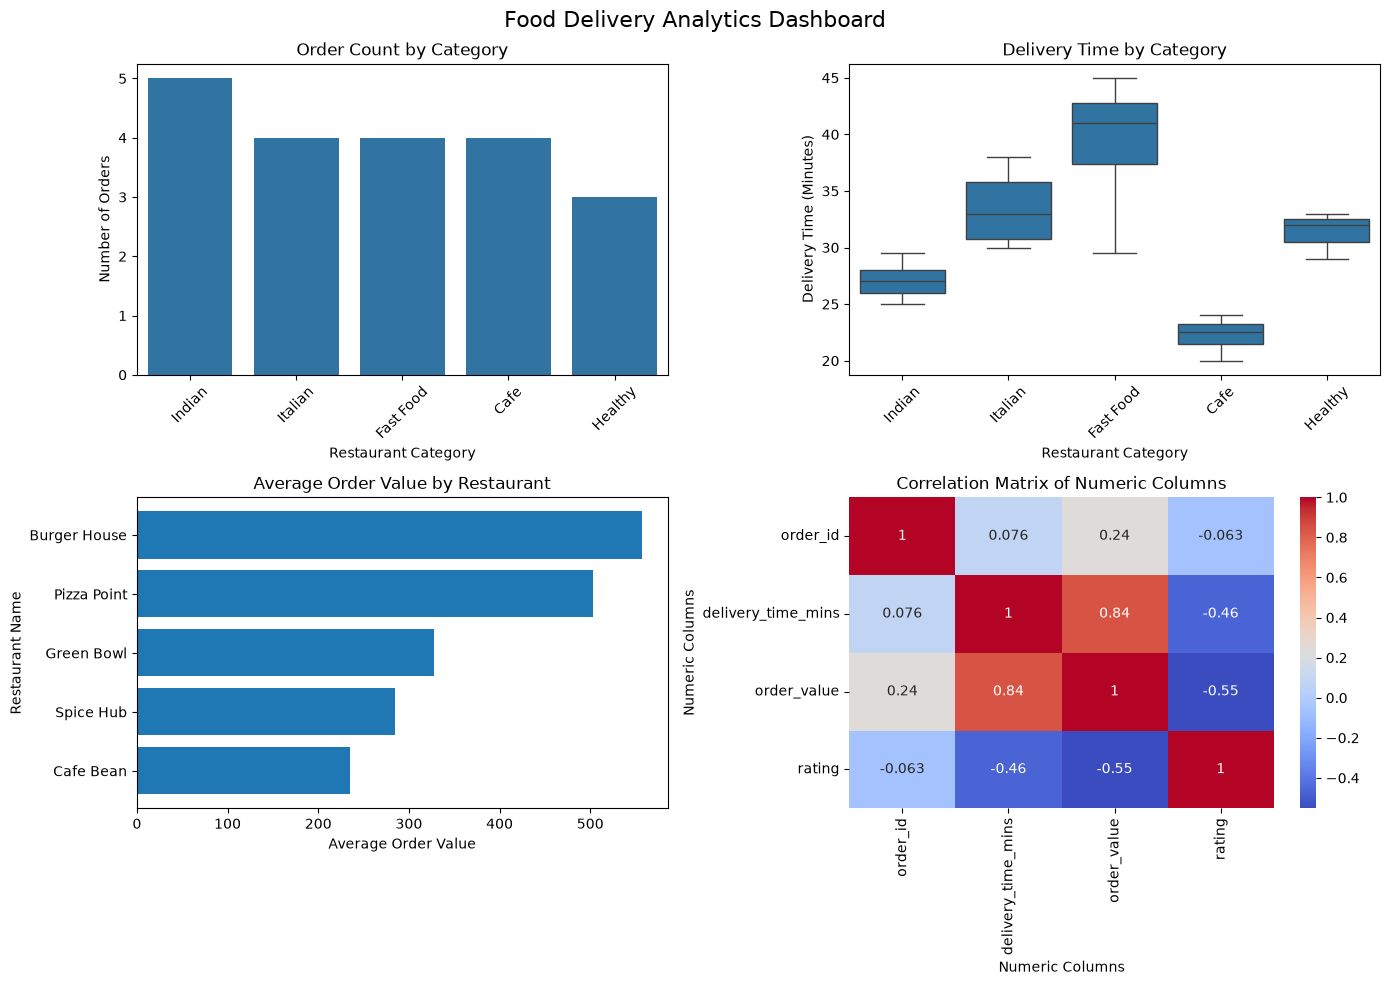

In [6]:

# Create a figure with 4 subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Countplot - orders per category
sns.countplot(data=df, x='category', ax=axes[0, 0])

axes[0, 0].set_title("Order Count by Category")
axes[0, 0].set_xlabel("Restaurant Category")
axes[0, 0].set_ylabel("Number of Orders")
axes[0, 0].tick_params(axis='x', rotation=45)


# Plot 2: Boxplot - delivery time by category
sns.boxplot(
    data=df,
    x='category',
    y='delivery_time_mins',
    ax=axes[0, 1]
)

axes[0, 1].set_title("Delivery Time by Category")
axes[0, 1].set_xlabel("Restaurant Category")
axes[0, 1].set_ylabel("Delivery Time (Minutes)")
axes[0, 1].tick_params(axis='x', rotation=45)


# Plot 3: Horizontal bar chart - average order value by restaurant
avg_order_value = df.groupby('restaurant_name')['order_value'].mean()

avg_order_value = avg_order_value.sort_values()

axes[1, 0].barh(
    avg_order_value.index,
    avg_order_value.values
)

axes[1, 0].set_title("Average Order Value by Restaurant")
axes[1, 0].set_xlabel("Average Order Value")
axes[1, 0].set_ylabel("Restaurant Name")


# Plot 4: Heatmap - correlation matrix
numeric_data = df.select_dtypes(include='number')
correlation_matrix = numeric_data.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    ax=axes[1, 1]
)

axes[1, 1].set_title("Correlation Matrix of Numeric Columns")
axes[1, 1].set_xlabel("Numeric Columns")
axes[1, 1].set_ylabel("Numeric Columns")


# Add main title and adjust spacing
fig.suptitle("Food Delivery Analytics Dashboard", fontsize=16)

plt.tight_layout()

# Save the dashboard
plt.savefig(
    'food_delivery_dashboard.png',
    dpi=150,
    bbox_inches='tight'
)

print("Dashboard saved as food_delivery_dashboard.png")

# Display the dashboard
plt.show()


1. Countplot — Order count by category
Shows how many orders belong to each category, such as Indian, Italian, and Cafe.

2. Boxplot — Delivery time by category
Compares delivery-time distributions, medians, spread, and potential outliers across categories.

3. Horizontal bar chart — Average order value
Compares the average order value of each restaurant.

4. Heatmap — Correlation matrix
Shows correlations between numeric columns. Values closer to +1 indicate positive relationships, while values closer to −1 indicate negative relationships.